# 03 — Waveform Integrity, Biophysical Lead Physics & 500 Hz Spectra (60 Hz US Mains)

Unlike PTB-XL (which provides human-annotated noise columns and `100 Hz` German recordings with `50 Hz` mains), Georgia 12-Lead ECG has **no pre-existing noise metadata columns** and is recorded at **`500 Hz` in the United States (`60 Hz` powerline mains)**.

This notebook inspects the quantitative `500 Hz` signal-quality metrics computed across all `10,334` readable Georgia ECGs:
1. **Signal Defects**: `NaN`/`Inf`, flatline/disconnected leads (`>= 500 ms`), extreme amplitude excursions (`> 10 mV`), large DC offsets (`> 0.5 mV`), and excessive baseline wander (`< 0.5 Hz`) or high-frequency noise (`> 45 Hz`).
2. **Biophysical Lead Consistency**: Verifying **Einthoven's Law** ($\text{II} = \text{I} + \text{III}$) and **Goldberger's Sum** ($\text{aVR} + \text{aVL} + \text{aVF} = 0$).
3. **`500 Hz` Ensemble Spectrum & `60 Hz` Mains Audit**: Measuring `60 Hz` powerline contamination and high-frequency energy.
4. **Clinical 12-Lead ECG Sheet & Ensemble Heartbeat Templates** across `NSR`, `AF`, `LBBB`, `RBBB`, `LVH`, and `TInv`.

Loaded 10,344 Georgia 12-Lead ECG records from error_labels.csv


=== Full-Cohort 500 Hz Signal Quality Summary (N = 10,334) ===
  err_sig_nan_or_inf                :     6 ( 0.06%)
  err_sig_flatline_lead             :    22 ( 0.21%)
  err_sig_extreme_amplitude         :    18 ( 0.17%)
  err_sig_large_dc_offset           :     7 ( 0.07%)
  err_sig_lead_physics_violation    :     1 ( 0.01%)
  err_sig_excessive_wander_or_hf    :    82 ( 0.79%)

Einthoven RMSE (µV) quantiles : {0.5: 0.72, 0.95: 0.76, 0.99: 0.78, 0.999: 0.8, 1.0: 476.91}
Goldberger RMSE (µV) quantiles: {0.5: 0.7, 0.95: 0.72, 0.99: 0.74, 0.999: 0.76, 1.0: 458.51}
60 Hz mains power share (%)   : {0.5: 0.04, 0.9: 0.15, 0.95: 0.24, 0.99: 0.94, 1.0: 62.3}


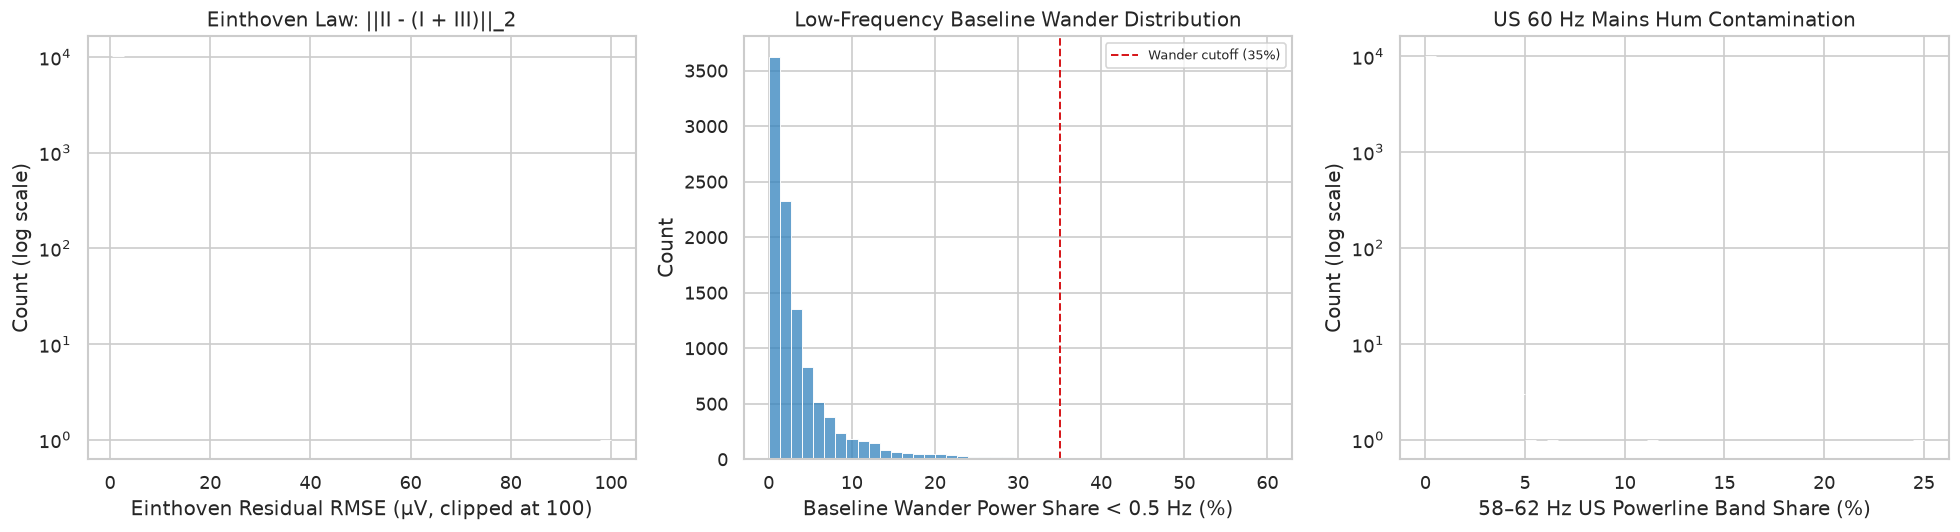

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wfdb

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "georgia_ecg" / "quality" / "error_labels.csv").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate georgia_ecg/quality/error_labels.csv from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from georgia_ecg import GeorgiaECGDataset

GEORGIA_DIR = REPO_ROOT / "georgia_ecg"
DATA_DIR = GEORGIA_DIR / "data"
LEADS = GeorgiaECGDataset.LEADS

df = pd.read_csv(GEORGIA_DIR / "quality" / "error_labels.csv", index_col="record_id")
df["snomed_codes"] = df["snomed_codes"].fillna("")
df["label_names"] = df["label_names"].fillna("")
df["error_tags"] = df["error_tags"].fillna("")
df["sex"] = df["sex"].fillna("")
print(f"Loaded {len(df):,} Georgia 12-Lead ECG records from error_labels.csv")

from concurrent.futures import ThreadPoolExecutor
from scipy import signal as sp_signal

valid_df = df[df["err_file_missing_or_corrupt"] == 0].copy()

print("=== Full-Cohort 500 Hz Signal Quality Summary (N = {:,}) ===".format(len(valid_df)))
for col in [
    "err_sig_nan_or_inf",
    "err_sig_flatline_lead",
    "err_sig_extreme_amplitude",
    "err_sig_large_dc_offset",
    "err_sig_lead_physics_violation",
    "err_sig_excessive_wander_or_hf",
]:
    cnt = int(valid_df[col].sum())
    print(f"  {col:<34}: {cnt:5,d} ({cnt/len(valid_df)*100:5.2f}%)")

print("\nEinthoven RMSE (µV) quantiles :", (valid_df["einthoven_rmse_mv"] * 1000).quantile([0.5, 0.95, 0.99, 0.999, 1.0]).round(2).to_dict())
print("Goldberger RMSE (µV) quantiles:", (valid_df["goldberger_rmse_mv"] * 1000).quantile([0.5, 0.95, 0.99, 0.999, 1.0]).round(2).to_dict())
print("60 Hz mains power share (%)   :", valid_df["mains_60hz_pct"].quantile([0.5, 0.90, 0.95, 0.99, 1.0]).round(2).to_dict())

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.6))

sns.histplot(valid_df["einthoven_rmse_mv"].clip(upper=0.1) * 1000.0, bins=45, log_scale=(False, True), color="#1b9e77", ax=axes[0])
axes[0].set_xlabel("Einthoven Residual RMSE (µV, clipped at 100)")
axes[0].set_ylabel("Count (log scale)")
axes[0].set_title("Einthoven Law: ||II - (I + III)||_2")

sns.histplot(valid_df["lf_wander_pct"].clip(upper=60), bins=45, color="#3182bd", ax=axes[1])
axes[1].axvline(35.0, color="#d7191c", ls="--", lw=1.2, label="Wander cutoff (35%)")
axes[1].set_xlabel("Baseline Wander Power Share < 0.5 Hz (%)")
axes[1].set_title("Low-Frequency Baseline Wander Distribution")
axes[1].legend(fontsize=8)

sns.histplot(valid_df["mains_60hz_pct"].clip(upper=25), bins=45, log_scale=(False, True), color="#e6550d", ax=axes[2])
axes[2].set_xlabel("58–62 Hz US Powerline Band Share (%)")
axes[2].set_ylabel("Count (log scale)")
axes[2].set_title("US 60 Hz Mains Hum Contamination")

plt.tight_layout()
plt.show()

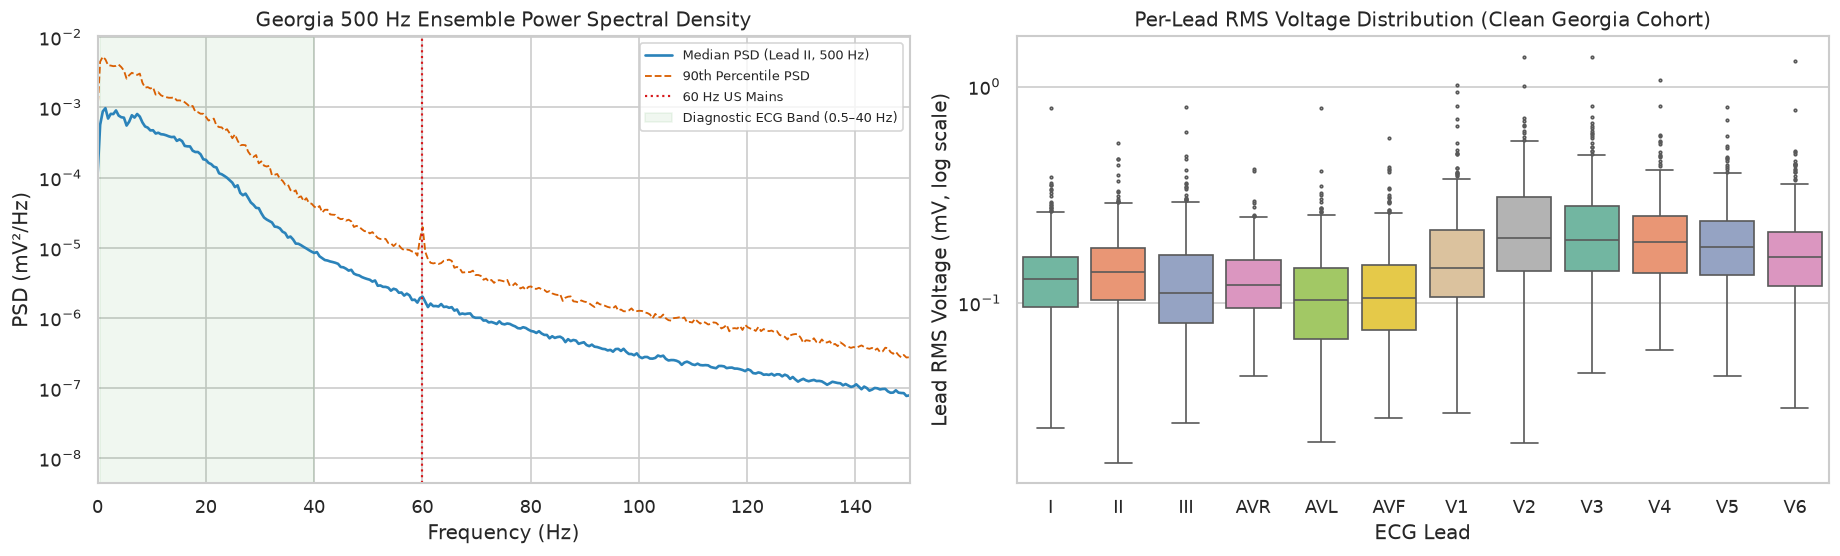

In [2]:
# Ensemble 500 Hz Welch PSD + Per-Lead RMS + 12-Lead Beat Templates across 500 clean records
rng = np.random.default_rng(42)
clean_pool = valid_df[valid_df["severity_tier"] == "0_clean"]
psd_ids = rng.choice(clean_pool.index.to_numpy(), size=min(400, len(clean_pool)), replace=False)

def load_psd_and_rms(rec_id: str):
    sig, _ = wfdb.rdsamp(str(DATA_DIR / valid_df.loc[rec_id, "record_path"]))
    sig = np.nan_to_num(sig)
    f, p = sp_signal.welch(sig[:, 1], fs=500.0, nperseg=1024)
    rms = np.sqrt(np.mean(sig ** 2, axis=0))
    return f, p, rms

with ThreadPoolExecutor(max_workers=16) as pool:
    res = list(pool.map(load_psd_and_rms, psd_ids))

f500 = res[0][0]
psd_med = np.median(np.vstack([x[1] for x in res]), axis=0)
psd_p90 = np.percentile(np.vstack([x[1] for x in res]), 90, axis=0)
rms_mat = np.vstack([x[2] for x in res])

fig, axes = plt.subplots(1, 2, figsize=(15.5, 4.8))

axes[0].semilogy(f500, psd_med, color="#2b83ba", lw=1.6, label="Median PSD (Lead II, 500 Hz)")
axes[0].semilogy(f500, psd_p90, color="#d95f02", lw=1.1, ls="--", label="90th Percentile PSD")
axes[0].axvline(60, color="#d7191c", ls=":", lw=1.3, label="60 Hz US Mains")
axes[0].axvspan(0.5, 40, color="green", alpha=0.06, label="Diagnostic ECG Band (0.5–40 Hz)")
axes[0].set_xlim(0, 150)
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("PSD (mV²/Hz)")
axes[0].set_title("Georgia 500 Hz Ensemble Power Spectral Density")
axes[0].legend(fontsize=8)

sns.boxplot(data=pd.DataFrame(np.clip(rms_mat, 1e-4, 5.0), columns=LEADS), ax=axes[1], fliersize=1.5, palette="Set2")
axes[1].set_yscale("log")
axes[1].set_ylabel("Lead RMS Voltage (mV, log scale)")
axes[1].set_xlabel("ECG Lead")
axes[1].set_title("Per-Lead RMS Voltage Distribution (Clean Georgia Cohort)")

plt.tight_layout()
plt.show()

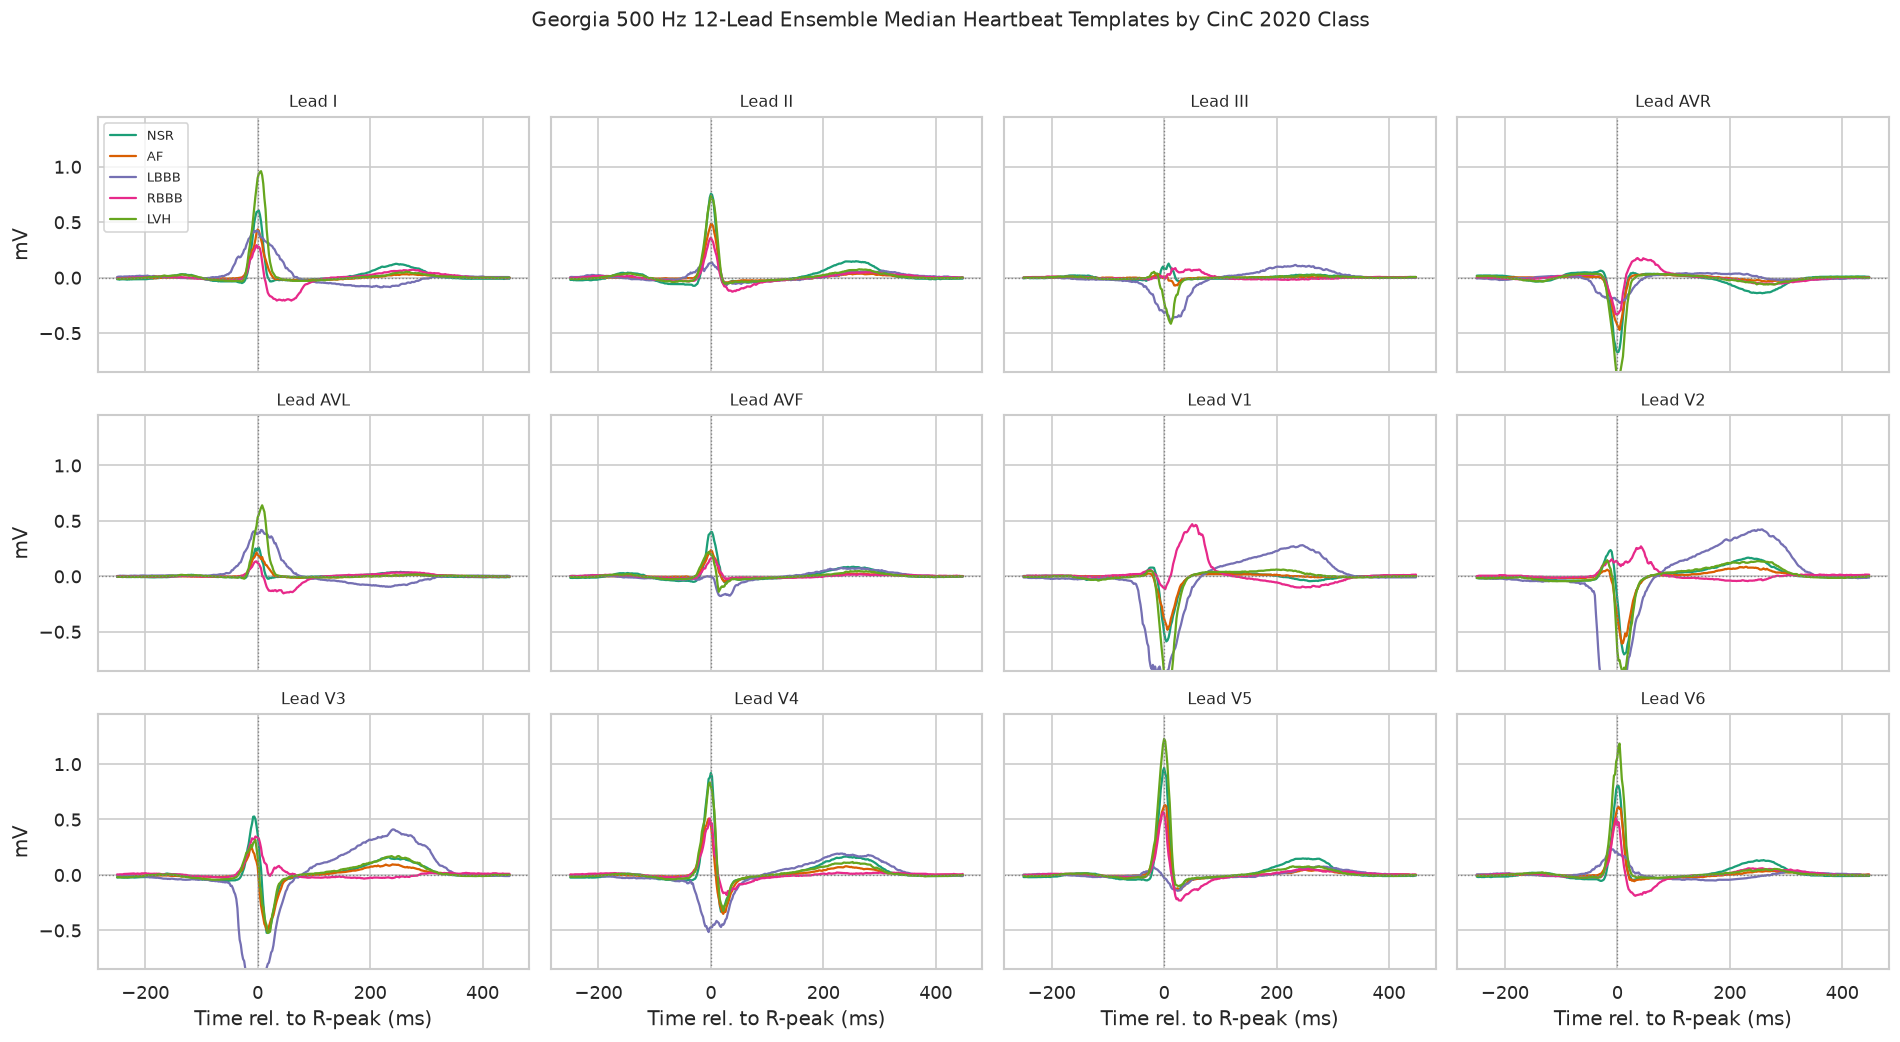

In [3]:
# Clinical 12-Lead Sheet + 12-Lead Ensemble Beat Templates for Major CinC 2020 Classes
b_qrs, a_qrs = sp_signal.butter(3, [5.0 / 250.0, 20.0 / 250.0], btype="bandpass")

target_classes = {
    "NSR":  "426783006",
    "AF":   "164889003",
    "LBBB": "164909002",
    "RBBB": "59118001",
    "LVH":  "164873001",
}

def extract_beat_500(rec_id: str):
    sig, _ = wfdb.rdsamp(str(DATA_DIR / valid_df.loc[rec_id, "record_path"]))
    sig = np.nan_to_num(sig)
    s0 = sig - np.median(sig, axis=0, keepdims=True)
    e = sp_signal.filtfilt(b_qrs, a_qrs, s0[:, 1]) ** 2
    pks, _ = sp_signal.find_peaks(e, distance=140, height=max(float(np.percentile(e, 85)) * 1.4, 1e-4))
    valid_p = [p for p in pks if 125 <= p < s0.shape[0] - 225]
    if len(valid_p) < 2:
        return None
    beats = np.stack([s0[p - 125 : p + 225, :] for p in valid_p], axis=0)  # (B, 350, 12)
    return np.median(beats, axis=0)

beats_by_cls = {}
for cname, code_str in target_classes.items():
    pool_ids = valid_df.index[valid_df["snomed_codes"].str.contains(code_str) & (valid_df["err_sig_flatline_lead"] == 0) & (valid_df["err_sig_extreme_amplitude"] == 0)]
    chosen = rng.choice(pool_ids.to_numpy(), size=min(120, len(pool_ids)), replace=False)
    with ThreadPoolExecutor(max_workers=16) as pool:
        beats = [b for b in pool.map(extract_beat_500, chosen) if b is not None]
    beats_by_cls[cname] = beats

t_ms = np.arange(-125, 225) * 2.0  # 2 ms per sample at 500 Hz
fig, axes = plt.subplots(3, 4, figsize=(16, 8.5), sharex=True, sharey=True)
axes = axes.ravel()
pal = {"NSR": "#1b9e77", "AF": "#d95f02", "LBBB": "#7570b3", "RBBB": "#e7298a", "LVH": "#66a61e"}

for j, lname in enumerate(LEADS):
    ax = axes[j]
    for cname, blist in beats_by_cls.items():
        if not blist:
            continue
        arr = np.stack([b[:, j] for b in blist], axis=0)
        ax.plot(t_ms, np.median(arr, axis=0), color=pal[cname], lw=1.35, label=cname)
    ax.axvline(0, color="gray", ls=":", lw=0.8)
    ax.axhline(0, color="gray", ls=":", lw=0.8)
    ax.set_title(f"Lead {lname}", fontsize=9.5)
    ax.set_ylim(-0.85, 1.45)

axes[0].legend(fontsize=8, loc="upper left")
for ax in axes[8:]:
    ax.set_xlabel("Time rel. to R-peak (ms)")
for idx in [0, 4, 8]:
    axes[idx].set_ylabel("mV")
fig.suptitle("Georgia 500 Hz 12-Lead Ensemble Median Heartbeat Templates by CinC 2020 Class", y=1.02, fontsize=12)
plt.tight_layout()
plt.show()